In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import networkx as nx
from newick import read

In [4]:
# trees = read("../data/smalt/41592_2021_1325_MOESM7_ESM_2.txt")

In [5]:
from ete3 import Tree

t = Tree("../data/smalt/41592_2021_1325_MOESM7_ESM_2.txt", format=2)


In [6]:
t.describe()


Number of leaf nodes:	5421
Total number of nodes:	10841
Rooted:	Yes
Most distant node:	T3692
Max. distance:	0.088913


In [7]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [8]:
T = ete_to_nx(t)

In [10]:
from plotters import draw_ultrametric_tree

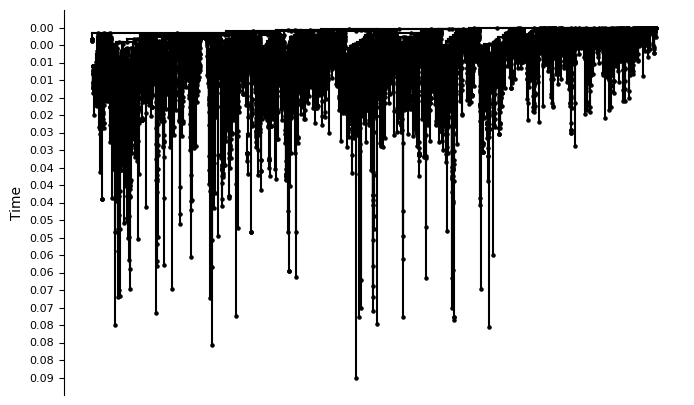

In [57]:
draw_ultrametric_tree(T, root=T.graph["root"], add_labels=False)

In [11]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 1.1641e-06}), (0, 10794, {'weight': 1.1641e-06}), (1, 2, {'weight': 1.1641e-06}), (1, 10793, {'weight': 2.7057e-06}), (2, 3, {'weight': 1.2223e-06}), (2, 10726, {'weight': 1.1641e-06}), (3, 4, {'weight': 1.1641e-06}), (3, 10725, {'weight': 2.7057e-06}), (4, 5, {'weight': 1.4667e-06}), (4, 10724, {'weight': 1.1641e-06}), (5, 6, {'weight': 1.1641e-06}), (5, 10709, {'weight': 1.3969e-06}), (6, 7, {'weight': 2.9696e-06}), (6, 10686, {'weight': 1.1641e-06}), (7, 8, {'weight': 3.0018e-06}), (7, 10679, {'weight': 0.000467079}), (8, 9, {'weight': 1.1641e-06}), (8, 10560, {'weight': 1.1641e-06}), (9, 10, {'weight': 2.3049e-06}), (9, 10457, {'weight': 1.1641e-06}), (10, 11, {'weight': 1.1641e-06}), (10, 10316, {'weight': 1.5482e-06}), (11, 12, {'weight': 1.1641e-06}), (11, 10315, {'weight': 2.7057e-06}), (12, 13, {'weight': 1.1641e-06}), (12, 10252, {'weight': 1.1641e-06}), (13, 14, {'weight': 2.2409e-06}), (13, 10165, {'weight': 2.5144e-06}), (14, 15, {'weight

In [12]:
T.nodes(data=True)

NodeDataView({0: {'name': '', 'dist': 2.7057e-06, 'is_leaf': False}, 1: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 2: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 3: {'name': '', 'dist': 1.2223e-06, 'is_leaf': False}, 4: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 5: {'name': '', 'dist': 1.4667e-06, 'is_leaf': False}, 6: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 7: {'name': '', 'dist': 2.9696e-06, 'is_leaf': False}, 8: {'name': '', 'dist': 3.0018e-06, 'is_leaf': False}, 9: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 10: {'name': '', 'dist': 2.3049e-06, 'is_leaf': False}, 11: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 12: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 13: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 14: {'name': '', 'dist': 2.2409e-06, 'is_leaf': False}, 15: {'name': '', 'dist': 1.1641e-06, 'is_leaf': False}, 16: {'name': '', 'dist': 2.6146e-06, 'is_leaf': False}, 17: {'name': '', 'dist': 2.8527e-06, 'is_lea

In [13]:
import networkx as nx

def truncate_tree(G, threshold):
    """
    Truncate a tree at a given distance threshold.
    
    - Splits edges that cross the threshold
    - Removes portions beyond the threshold
    - Updates node 'dist' accordingly
    """
    G = G.copy()
    
    new_node_counter = 0
    edges_to_remove = []
    edges_to_add = []
    nodes_to_add = {}

    for u, v, d in list(G.edges(data=True)):
        weight = d.get("weight", 0)
        u_dist = G.nodes[u].get("dist", 0)
        v_dist = G.nodes[v].get("dist", u_dist + weight)

        # Case 1: entire edge is beyond threshold → remove
        if u_dist >= threshold:
            edges_to_remove.append((u, v))

        # Case 2: edge crosses threshold → split
        elif u_dist < threshold < v_dist:
            # distance from u to truncation point
            new_weight = threshold - u_dist
            
            new_node = f"trunc_{new_node_counter}"
            new_node_counter += 1

            # create truncated node
            nodes_to_add[new_node] = {
                "name": None,
                "dist": threshold,
                "is_leaf": True
            }

            # replace edge u->v with u->new_node
            edges_to_remove.append((u, v))
            edges_to_add.append((u, new_node, {"weight": new_weight}))

        # Case 3: fully within threshold → keep as is

    # Apply changes
    G.remove_edges_from(edges_to_remove)
    G.add_nodes_from(nodes_to_add.items())
    G.add_edges_from(edges_to_add)

    def keep_root_component(G):
        root = G.graph["root"]
        reachable = set(nx.descendants(G, root)) | {root}
        return G.subgraph(reachable).copy()

    G = keep_root_component(G)

    return G

In [14]:
Tt = truncate_tree(T, threshold=0.018)

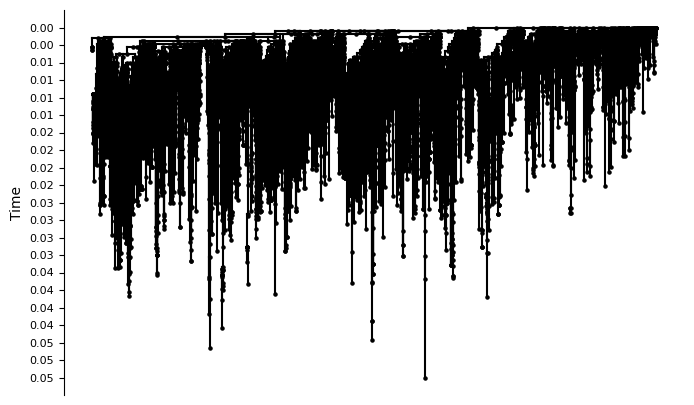

In [15]:
draw_ultrametric_tree(Tt, root=Tt.graph["root"], add_labels=False)

In [16]:
import networkx as nx

def truncate_tree_by_dist(G, root, threshold):
    """
    Truncate a tree so that:
      - any branch beyond `threshold` distance from root is cut
      - edges crossing the threshold are split
      - nodes beyond threshold are removed
      - 'dist' attributes are updated
    
    Parameters
    ----------
    G : nx.DiGraph
        Tree with edge attribute 'weight' (branch length) and node attribute 'dist'
    root : node
        Root of the tree
    threshold : float
        Maximum allowed distance from root
    """
    H = G.copy()
    new_node_counter = 0

    # First, ensure all node 'dist' are correct
    def compute_distances(H, root):
        dist = {root: 0}
        for u, v in nx.edge_dfs(H, source=root):
            dist[v] = dist[u] + H.edges[u, v]["weight"]
        nx.set_node_attributes(H, dist, "dist")
    
    compute_distances(H, root)

    # Step 1: truncate edges
    for u, v, d in list(H.edges(data=True)):
        u_dist = H.nodes[u]["dist"]
        edge_length = d["weight"]
        v_dist = u_dist + edge_length

        if u_dist >= threshold:
            # entire edge beyond threshold
            H.remove_edge(u, v)
            continue

        if v_dist > threshold:
            # edge crosses threshold → split
            new_node = f"trunc_{new_node_counter}"
            new_node_counter += 1
            H.add_node(new_node, dist=threshold, is_leaf=True)

            H.add_edge(u, new_node, weight=threshold - u_dist)
            H.remove_edge(u, v)

    # Step 2: remove disconnected nodes
    reachable = set(nx.descendants(H, root)) | {root}
    H = H.subgraph(reachable).copy()

    # Step 3: recompute 'dist' for remaining nodes
    compute_distances(H, root)

    return H

In [17]:
T_exact = truncate_tree_by_dist(Tt, root=Tt.graph["root"], threshold=0.018)

In [35]:
import networkx as nx

def prune_to_threshold_leaves(G, root, threshold):
    """
    Prune tree to remove leaf edges that do not reach threshold.
    Truncate edges that cross threshold. Internal edges are preserved.
    """
    H = G.copy()
    new_node_counter = 0

    # Compute distances from root
    dist = {root: 0}
    for u, v in nx.edge_dfs(H, source=root):
        dist[v] = dist[u] + H.edges[u, v]["weight"]
    nx.set_node_attributes(H, dist, "dist")

    # Step 1: process leaves
    for v in list(H.nodes):
        if H.out_degree(v) == 0:  # leaf
            u = next(H.predecessors(v))
            leaf_dist = H.nodes[v]["dist"]
            parent_dist = H.nodes[u]["dist"]
            if leaf_dist < threshold:
                # leaf does not reach threshold → remove
                H.remove_edge(u, v)
                H.remove_node(v)
            elif parent_dist < threshold < leaf_dist:
                # truncate leaf at threshold
                new_leaf = f"trunc_{new_node_counter}"
                new_node_counter += 1
                H.add_node(new_leaf, dist=threshold, is_leaf=True)
                H.add_edge(u, new_leaf, weight=threshold - parent_dist)
                H.remove_edge(u, v)
                H.remove_node(v)
    
    # Step 2: mark leaves
    for n in H.nodes:
        H.nodes[n]["is_leaf"] = H.out_degree(n) == 0

    # Step 3: remove disconnected nodes
    reachable = set(nx.descendants(H, root)) | {root}
    H = H.subgraph(reachable).copy()

    return H

In [36]:
T_extant = prune_to_threshold_leaves(T_exact, root=T_exact.graph["root"], threshold=0.0179999999)

In [37]:
T_exact.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 1.1641e-06}), (0, 10794, {'weight': 1.1641e-06}), (1, 2, {'weight': 1.1641e-06}), (1, 10793, {'weight': 2.7057e-06}), (2, 3, {'weight': 1.2223e-06}), (2, 10726, {'weight': 1.1641e-06}), (3, 4, {'weight': 1.1641e-06}), (3, 10725, {'weight': 2.7057e-06}), (4, 5, {'weight': 1.4667e-06}), (4, 10724, {'weight': 1.1641e-06}), (5, 6, {'weight': 1.1641e-06}), (5, 10709, {'weight': 1.3969e-06}), (6, 7, {'weight': 2.9696e-06}), (6, 10686, {'weight': 1.1641e-06}), (7, 8, {'weight': 3.0018e-06}), (7, 10679, {'weight': 0.000467079}), (8, 9, {'weight': 1.1641e-06}), (8, 10560, {'weight': 1.1641e-06}), (9, 10, {'weight': 2.3049e-06}), (9, 10457, {'weight': 1.1641e-06}), (10, 11, {'weight': 1.1641e-06}), (10, 10316, {'weight': 1.5482e-06}), (11, 12, {'weight': 1.1641e-06}), (11, 10315, {'weight': 2.7057e-06}), (12, 13, {'weight': 1.1641e-06}), (12, 10252, {'weight': 1.1641e-06}), (13, 14, {'weight': 2.2409e-06}), (13, 10165, {'weight': 2.5144e-06}), (14, 15, {'weight

In [38]:
T_extant.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 1.1641e-06}), (0, 10794, {'weight': 1.1641e-06}), (1, 2, {'weight': 1.1641e-06}), (2, 3, {'weight': 1.2223e-06}), (2, 10726, {'weight': 1.1641e-06}), (3, 4, {'weight': 1.1641e-06}), (4, 5, {'weight': 1.4667e-06}), (5, 6, {'weight': 1.1641e-06}), (5, 10709, {'weight': 1.3969e-06}), (6, 7, {'weight': 2.9696e-06}), (6, 10686, {'weight': 1.1641e-06}), (7, 8, {'weight': 3.0018e-06}), (7, 10679, {'weight': 0.000467079}), (8, 9, {'weight': 1.1641e-06}), (8, 10560, {'weight': 1.1641e-06}), (9, 10, {'weight': 2.3049e-06}), (9, 10457, {'weight': 1.1641e-06}), (10, 11, {'weight': 1.1641e-06}), (10, 10316, {'weight': 1.5482e-06}), (11, 12, {'weight': 1.1641e-06}), (12, 13, {'weight': 1.1641e-06}), (12, 10252, {'weight': 1.1641e-06}), (13, 14, {'weight': 2.2409e-06}), (13, 10165, {'weight': 2.5144e-06}), (14, 15, {'weight': 1.1641e-06}), (14, 9666, {'weight': 1.1641e-06}), (15, 16, {'weight': 2.6146e-06}), (15, 8311, {'weight': 2.7888e-06}), (16, 17, {'weight': 2.

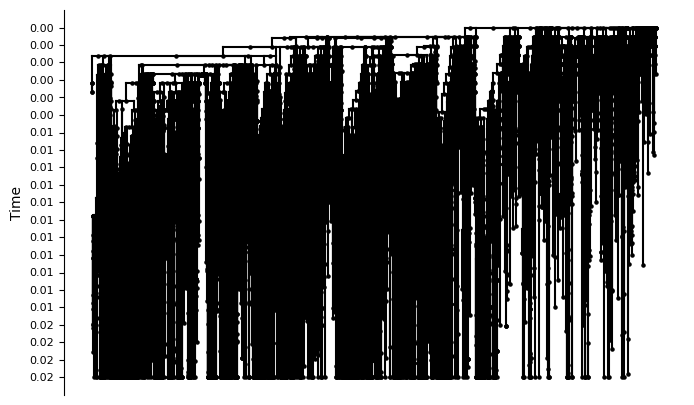

In [40]:
draw_ultrametric_tree(T_exact, root=T_exact.graph["root"], add_labels=False)

In [43]:
import networkx as nx

def add_edge_times(G, root):
    """
    Add start_time and end_time to each edge based on edge weights.
    
    Assumes:
      - G is a directed tree
      - edge attribute 'weight' exists
      - root is known
    """
    G = G.copy()

    # Step 1: compute distances from root (node times)
    dist = {root: 0}
    for u, v in nx.edge_dfs(G, source=root):
        dist[v] = dist[u] + G.edges[u, v]["weight"]

    nx.set_node_attributes(G, dist, "dist")

    # Step 2: assign start_time and end_time to edges
    for u, v in G.edges:
        start_time = dist[u]
        end_time = dist[v]

        G.edges[u, v]["start_time"] = start_time
        G.edges[u, v]["end_time"] = end_time

    return G

In [44]:
T_exact = add_edge_times(T_exact, root=T_exact.graph["root"])

In [46]:
for n in T_exact.nodes:
    children = list(T_exact.successors(n))

    if len(children) == 0:
        if T_exact.nodes[n].get("dist", 0) < 0.018 - 1e-9:
            T_exact.nodes[n]["event"] = "death"
        else:
            T_exact.nodes[n]["event"] = "sampled"

    elif len(children) > 1:
        T_exact.nodes[n]["event"] = "birth"

    else:
        raise Exception(f"Unexpected node with 1 successor: {n}")

In [50]:
def filter_extant_lineages(G, root):
    """
    Prune tree bottom-up to keep only extant lineages.
    Birth nodes with only one surviving child are contracted.
    """

    H = G.copy()

    # process nodes in postorder (bottom-up)
    for v in list(nx.dfs_postorder_nodes(H, source=root)):
        if v == root:
            continue

        event = H.nodes[v]["event"]
        parent = next(iter(H.predecessors(v)), None)

        # ---------- rule 1: death events ----------
        if event == "death":
            if parent is not None:
                H.remove_edge(parent, v)
            H.remove_node(v)
            continue

        # ---------- rule 2 & 3: birth events ----------
        if event == "birth" or event == "diff":
            children = list(H.successors(v))

            # no surviving children → delete birth
            if len(children) == 0:
                if parent is not None:
                    H.remove_edge(parent, v)
                H.remove_node(v)

            # exactly one surviving child → contract
            elif len(children) == 1:
                c = children[0]

                if parent is not None:
                    # original edges
                    e1 = H.edges[parent, v]
                    e2 = H.edges[v, c]

                    # create contracted edge
                    H.add_edge(
                        parent,
                        c,
                        start_time=e1["start_time"],
                        end_time=e2["end_time"],
                        weight=e2["end_time"] - e1["start_time"]
                    )

                    H.remove_edge(parent, v)

                H.remove_edge(v, c)
                H.remove_node(v)

            # two children → keep as is
            elif len(children) == 2:
                pass

            else:
                raise RuntimeError("Birth node with >2 children")

    return H



In [51]:
T_extant = filter_extant_lineages(T_exact, root=T_exact.graph["root"])

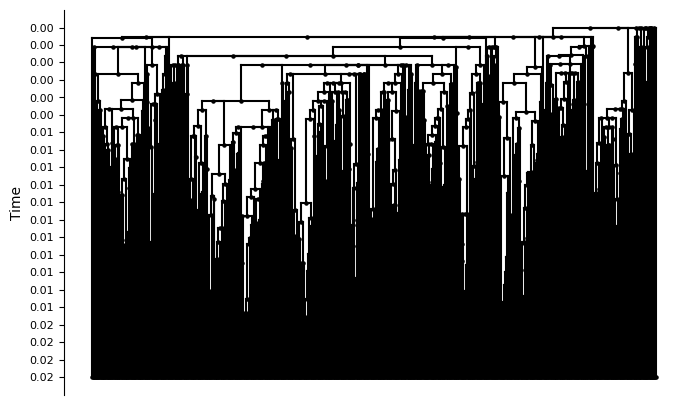

In [52]:
draw_ultrametric_tree(T_extant, root=T_extant.graph["root"], add_labels=False)

In [55]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def plot_ltt(
    trees,
    weight_key='length',
    log_scale=True,
):
    
    all_branching_times = []
    
    for T in trees:
        root = [n for n in T.nodes if T.in_degree(n) == 0][0]

        node_times = {}
        def dfs(node, current_time):
            node_times[node] = current_time
            for child in T.successors(node):
                w = T.edges[node, child].get(weight_key, 0.0)
                dfs(child, current_time + w)

        dfs(root, 0.0)

        branching_times = [
            node_times[n]
            for n in T.nodes
            if T.out_degree(n) >= 2
        ]
        all_branching_times.extend(branching_times)

    all_branching_times = np.sort(all_branching_times)

    times = np.insert(all_branching_times, 0, 0.0)
    lineages = np.arange(1, len(times) + 1)

    fig, ax = plt.subplots()

    ax.step(times, lineages, where='post')

    ax.set_xlabel("Time")
    ax.set_ylabel("Number of lineages")

    if log_scale:
        ax.set_yscale("log")

    ax.set_title("Lineage Through Time (LTT)")

    return times, lineages

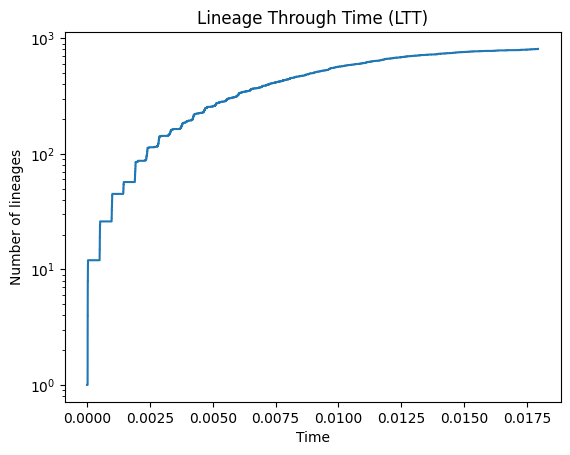

In [56]:
plot_ltt([T_extant], weight_key="weight", log_scale=True)
plt.show()